In [1]:
import json
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import os
import pathlib
import pickle
import sys
from tqdm import tqdm

import torch

from plots import plot_pos, scatter_pos, stemplot, violinplot, add_border_and_ticks
from helpers import optimal_decoder, gather_models, gather_test_data, momentum_plaus, \
                    dict_to_csv, wd_types_to_csvs, array_to_heatmap
from metrics import wasserstein, calc_wds

os.makedirs('pickle', exist_ok=True)
replay_dict_path = 'pickle/replay_biased_tanh_plaus.pkl'

## Load models and data

In [2]:
# Hyperparameters
unmask_every = 3
epoch = 15000 
#epoch = 5000 #2500
t_quiescent = 500 #1000 #1000 #250 #100
quiescence = "same" 
lambda_scaling = False

In [3]:
results = pathlib.Path("../results")
noise = 0.0001
config_name = f"noisy_biased_unmask_every_{unmask_every}_{noise}"
seed_dirs = [results / "spatial_navigation/tanh" / f \
             for f in os.listdir(results / "spatial_navigation/tanh") if config_name in f]
seed_dirs

[PosixPath('../results/spatial_navigation/tanh/noisy_biased_unmask_every_3_0.0001_11'),
 PosixPath('../results/spatial_navigation/tanh/noisy_biased_unmask_every_3_0.0001_14'),
 PosixPath('../results/spatial_navigation/tanh/noisy_biased_unmask_every_3_0.0001_10'),
 PosixPath('../results/spatial_navigation/tanh/noisy_biased_unmask_every_3_0.0001_13'),
 PosixPath('../results/spatial_navigation/tanh/noisy_biased_unmask_every_3_0.0001_12')]

In [4]:
# Load models and their test data
models = gather_models(seed_dirs, epoch)
test_obs, test_pos, test_inits = gather_test_data(models)

## Simulating the model with various parameters

In [5]:
tau_a = 100
lambda_v_vals = [1, 0.7, 0.5, 0.3]
b_a_vals = [0, 0.01, 0.02, 0.03]

In [6]:
replay = {}
quiescent_inputs = torch.zeros(models[0].task.batch_size, t_quiescent, 2)
for lambda_v in lambda_v_vals:
    for b_a in b_a_vals:
        key = str({'lambda_v': lambda_v, 'tau_a': tau_a, 'b_a': b_a})
        print(key)        
        replay[key] = []
        for (model, init) in zip(models, test_inits):
            # plausible momentum!
            pc_act = momentum_plaus(
                model, lambda_v=lambda_v, tau_a=tau_a, b_a=b_a, quiescence=quiescence,
                lambda_scaling=lambda_scaling, x=quiescent_inputs, init_state=init)[1]
            replay[key].append(optimal_decoder(
                model, pc_act, lr=(2e-1 if quiescence=='scaled' else 1e-1),
                verbose=True, iters=51))
        replay[key] = torch.stack(replay[key])

{'lambda_v': 1, 'tau_a': 100, 'b_a': 0}
0 1.5089159205672331e-05
5 1.480942501075333e-05
10 1.4596244000131264e-05
15 1.4442441170103848e-05
20 1.4336074855236802e-05
25 1.4263763659982942e-05
30 1.4213849681254942e-05
35 1.4177856428432278e-05
40 1.415040242136456e-05
45 1.4128365364740603e-05
50 1.4110036318015773e-05
0 1.0409004971734248e-05
5 9.880727702693548e-06
10 9.448263881495222e-06
15 9.112230145547073e-06
20 8.864144547260366e-06
25 8.688799425726756e-06
30 8.567975783080328e-06
35 8.484365025651641e-06
40 8.42428289615782e-06
45 8.378548955079168e-06
50 8.341841748915613e-06
0 1.6754536773078144e-05
5 1.5732086467323825e-05
10 1.5391953638754785e-05
15 1.528646498627495e-05
20 1.5235626960929949e-05
25 1.5194410480035003e-05
30 1.5162168892857153e-05
35 1.514196083007846e-05
40 1.513123879703926e-05
45 1.5125265235838015e-05
50 1.5120946954993997e-05
0 1.0455221854499541e-05
5 9.679517461336218e-06
10 9.3118478616816e-06
15 9.152214261121117e-06
20 9.08036145119695e-06
25 

45 8.616564628027845e-06
50 8.598402928328142e-06
0 9.612802386982366e-06
5 9.425266398466192e-06
10 9.277665412810165e-06
15 9.162698916043155e-06
20 9.07289268070599e-06
25 9.002254955703393e-06
30 8.946564776124433e-06
35 8.902843546820804e-06
40 8.868785698723514e-06
45 8.842435818223748e-06
50 8.82211224961793e-06
{'lambda_v': 0.8, 'tau_a': 100, 'b_a': 3}
0 1.4525374353979714e-05
5 1.4220146113075316e-05
10 1.3981144547869917e-05
15 1.3801878594676964e-05
20 1.3672056411451194e-05
25 1.358010558760725e-05
30 1.3515348655346315e-05
35 1.3469230907503515e-05
40 1.3435569599096198e-05
45 1.3410224710241891e-05
50 1.339054597337963e-05
0 1.0783514881040901e-05
5 1.0250232662656344e-05
10 9.809267794480547e-06
15 9.461676199862268e-06
20 9.199865417031106e-06
25 9.00983013707446e-06
30 8.87464193510823e-06
35 8.778039045864716e-06
40 8.7069302026066e-06
45 8.65226138557773e-06
50 8.608524694864172e-06
0 1.1305492989777122e-05
5 1.0874360668822192e-05
10 1.0548028512857854e-05
15 1.0308

30 1.0700105121941306e-05
35 1.0622882655297872e-05
40 1.0565671800577547e-05
45 1.0523054697841872e-05
50 1.0491196007933468e-05
0 1.8506161723053083e-05
5 1.8143120541935787e-05
10 1.7826569091994315e-05
15 1.7552467397763394e-05
20 1.7315611330559477e-05
25 1.7110834960476495e-05
30 1.693353260634467e-05
35 1.6779740690253675e-05
40 1.6646097719785757e-05
45 1.6529782442376018e-05
50 1.64284065249376e-05
0 1.2183422768430319e-05
5 1.2009193596895784e-05
10 1.185939345305087e-05
15 1.173218151961919e-05
20 1.1625224033195991e-05
25 1.1536110832821578e-05
30 1.1462527254479937e-05
35 1.1402278687455691e-05
40 1.1353295121807605e-05
45 1.1313661161693744e-05
50 1.128166877606418e-05
{'lambda_v': 0.5, 'tau_a': 100, 'b_a': 0}
0 1.538788819743786e-05
5 1.501490805821959e-05
10 1.4730956536368467e-05
15 1.4527669918606989e-05
20 1.4389011994353496e-05
25 1.4296433619165327e-05
30 1.4233769434213173e-05
35 1.4189401554176584e-05
40 1.4156069482851308e-05
45 1.412965139024891e-05
50 1.410793

In [9]:
# save replays
with open(replay_dict_path, 'wb') as file:
    pickle.dump(replay, file)

In [10]:
# load replays
with open(replay_dict_path, 'rb') as file:
    replay = pickle.load(file)

In [7]:
list(replay.values())[0].shape # seeds, N, T, 2

torch.Size([5, 200, 500, 2])

## Decoded outputs

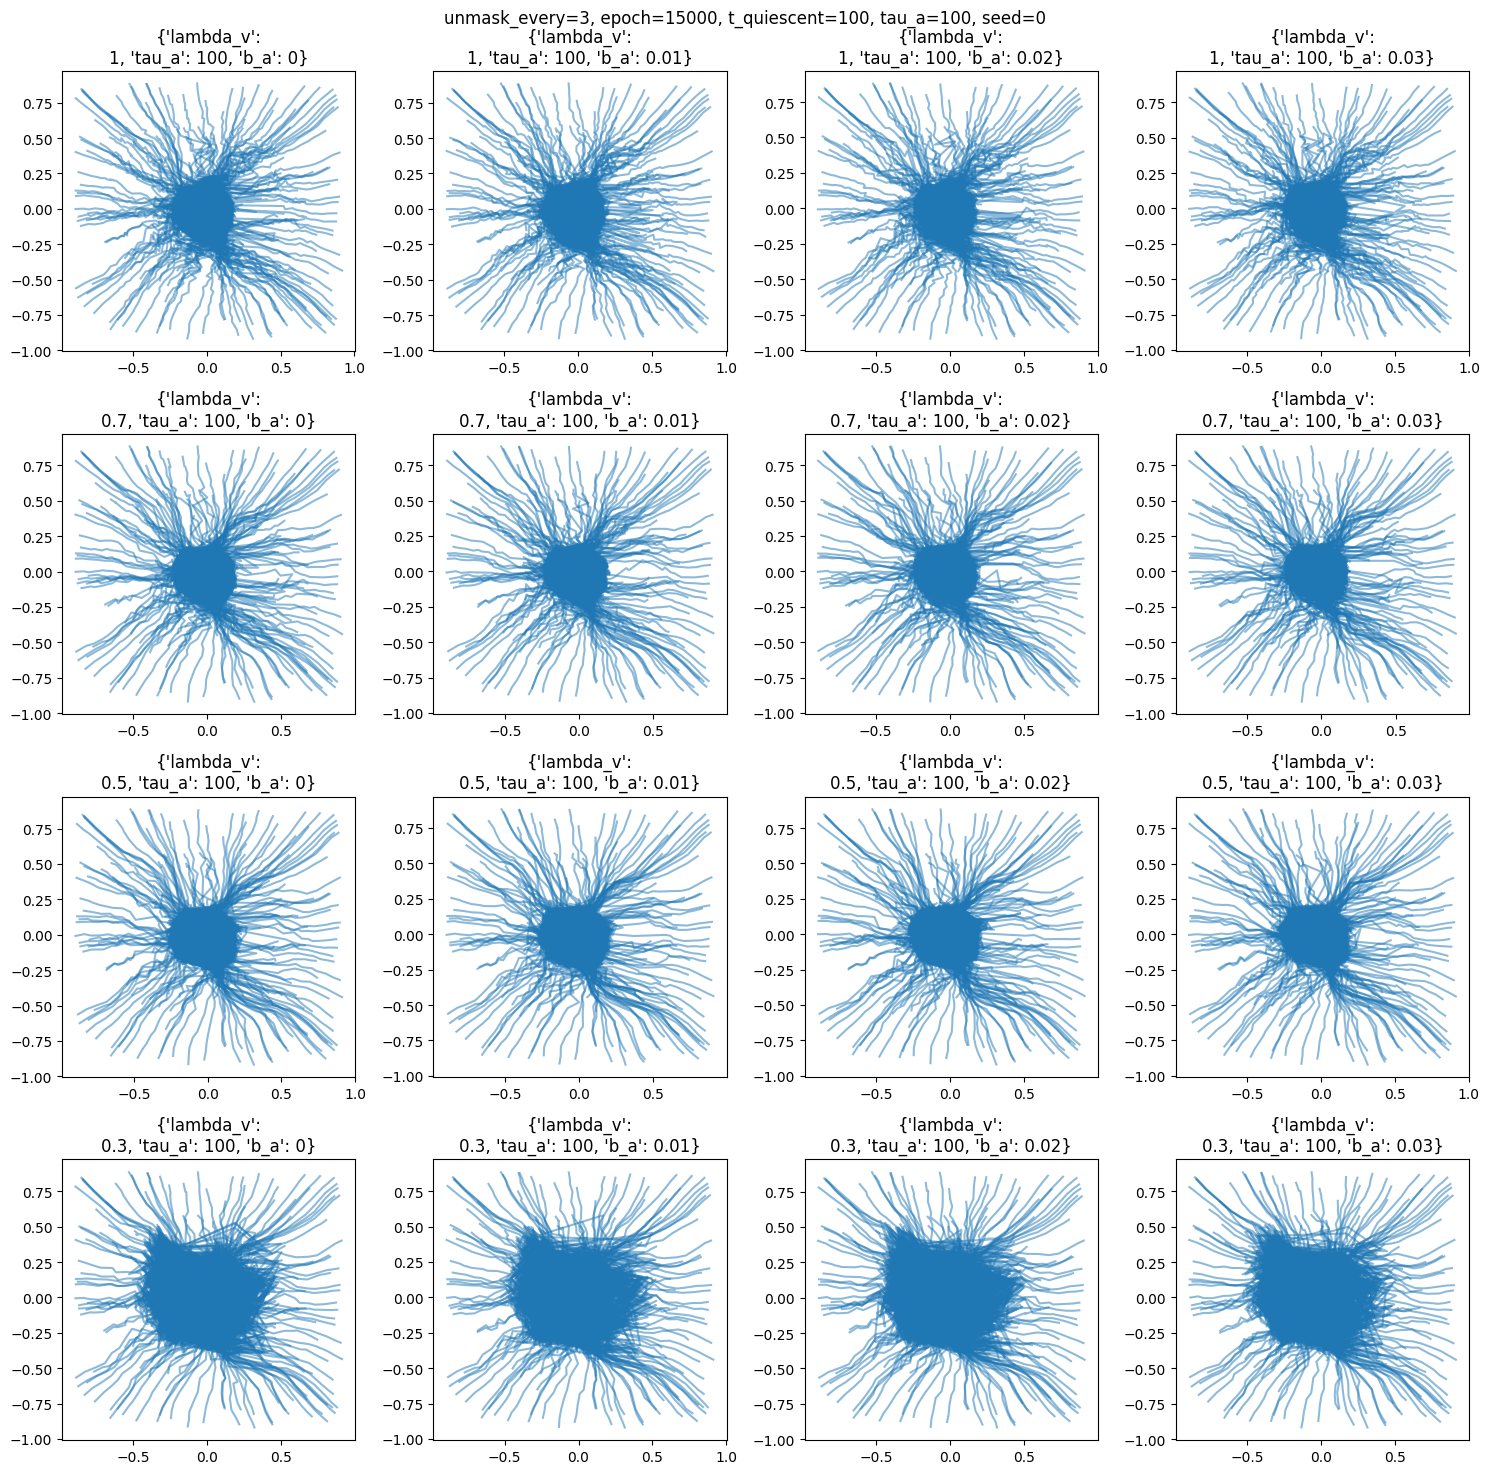

In [8]:
seed_idx = 0
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(15,15))
axs = axs.flatten()
for i,(k,v) in enumerate(replay.items()):
    plot_pos(axs[i], v[seed_idx,:,:100], title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
fig.suptitle(f'{unmask_every=}, {epoch=}, t_quiescent=100, {tau_a=}, seed={seed_idx}')
fig.tight_layout()

## Wasserstein distance

In [11]:
wds = calc_wds(replay, test_pos)

100%|███████████████████████████████████████████| 16/16 [00:23<00:00,  1.45s/it]


In [12]:
dict_to_csv(wds, 'b_a', path='../csv/plaus_tanh_wds_biased.csv')

,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02,b_a=0.03
0,1.0,100,0.083160,0.086443,0.089718,0.093027
1,0.7,100,0.094479,0.097590,0.100998,0.104720
2,0.5,100,0.103226,0.107607,0.113019,0.113877
3,0.3,100,0.115712,0.117793,0.119251,0.121842


## Reach times

In [13]:
inner_radius, outer_radius = 0.2, 0.45

In [14]:
reach_times, rt_meds, rt_avgs = {}, {}, {}
for (k,v) in list(replay.items()) + [('awake', test_pos)]:
    assert v.ndim == 4 # seed, N, T, 2
    radii = v.flatten(0,1).square().sum(-1).sqrt()
    success = ((radii > inner_radius) & (radii < outer_radius)).int()
    #assert 0 not in success.sum(1) # make sure the conditions have been met at least once
    reach_times[k] = success.argmax(dim=1)
    rt_meds[k] = reach_times[k].float().median().item()
    rt_avgs[k] = reach_times[k].float().mean().item()
awake_reach_times = reach_times.pop('awake')
awake_rt_med = rt_meds.pop('awake')
awake_rt_avg = rt_avgs.pop('awake')

In [15]:
delta_arrays = {
    'median':  (np.array(list(rt_meds.values())).reshape(4,4) / awake_rt_med - 1) * 100,
    'average': (np.array(list(rt_avgs.values())).reshape(4,4) / awake_rt_avg - 1) * 100
}

In [16]:
print(delta_arrays['median'], '\n')
print(delta_arrays['average'], '\n')
print('min: ', min(delta_arrays['median'].min(), delta_arrays['average'].min()))
print('max: ', max(delta_arrays['median'].max(), delta_arrays['average'].max()))

os.makedirs('../csv/rt', exist_ok=True)
array_to_heatmap(delta_arrays['median'],  '../csv/rt/plaus_tanh_med_rt_heatmap_biased.txt')
array_to_heatmap(delta_arrays['average'], '../csv/rt/plaus_tanh_avg_rt_heatmap_biased.txt');

[[-15.38461538 -15.38461538 -15.38461538 -15.38461538]
 [-30.76923077 -30.76923077 -30.76923077 -38.46153846]
 [-38.46153846 -38.46153846 -38.46153846 -38.46153846]
 [-46.15384615 -46.15384615 -46.15384615 -46.15384615]] 

[[-29.7873659  -32.05837788 -33.61851971 -37.50629043]
 [-34.34197072 -45.26295758 -48.0309529  -38.73930566]
 [-51.90613975 -51.91243019 -50.22018022 -52.88122915]
 [-61.92752843 -61.98414534 -62.03447482 -62.14770865]] 

min:  -62.147708649854906
max:  -15.384615384615385
Make sure to add newlines before plotting in TikZ
Make sure to add newlines before plotting in TikZ


## Distances traveled

In [17]:
def calculate_path_lens(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # differentiate along T (dim 1),
    # calculate dx (square sum sqrt),
    # sum along T (now dim -1)
    return x.diff(dim=1).square().sum(-1).sqrt().sum(-1)

dist_avg = {}
for k, x_hat in replay.items():
    # combine seed and sample dim. x_hat shape = (-1, timesteps, 2)
    x_hat = x_hat.flatten(0,1)
    path_lens = calculate_path_lens(x_hat)
    dist_avg[k] = path_lens.mean().item()

In [18]:
print(calculate_path_lens(test_pos.flatten(0,1)).mean().item())
dict_to_csv(dist_avg, col_param='b_a', path='../csv/exploration/plaus_tanh_exploration_distance_biased.csv')

1.722671627998352


,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02,b_a=0.03
0,1.0,100,20.511238,21.092934,22.828680,22.588144
1,0.7,100,20.871544,21.898981,23.595251,22.999107
2,0.5,100,33.382561,33.573257,35.131660,34.670204
3,0.3,100,77.097015,77.680275,78.225586,78.394859
